# 🛍️ Multiclass Category Prediction — Shopping Trends
**End-to-end ML project: data → model → deployed website (runs fully in Google Colab)**

Run the cells from top to bottom (`Runtime → Run all`). When asked, upload `shopping_trends.csv`.

## 1. Problem Definition

**What problem are we solving?**  
Given the details of a purchase (item, size, colour, season, price, customer attributes…), predict which **product category** it belongs to: `Clothing`, `Accessories`, `Footwear` or `Outerwear`. This is a **multiclass classification** problem (4 classes).

**Why is it important?**  
Retailers handle thousands of products and transactions. Automatically assigning the right category keeps catalogues clean, powers search filters and recommendations, supports inventory planning, and removes slow manual tagging.

**Who will use it?**  
E-commerce catalogue / merchandising teams, marketing & analytics teams, and inventory planners.

**Expected output?**  
One predicted category (one of the 4 classes) together with the probability for each class, shown on a simple website.

## 2. Dataset Collection

**Source:** *Customer Shopping Trends Dataset* (Kaggle, public dataset of 3,900 retail purchases).  
**File:** `shopping_trends.csv` — upload it in the next cell.  
**Target column:** `Category` (Clothing / Accessories / Footwear / Outerwear).

| Column | Meaning |
|---|---|
| Customer ID | Unique id of the customer |
| Age, Gender | Customer demographics |
| Item Purchased | Specific product (Blouse, Sneakers, Jewelry…) |
| **Category** | **Target – product category** |
| Purchase Amount (USD) | Price paid |
| Location | US state of the customer |
| Size, Color | Product size / colour |
| Season | Season of purchase |
| Review Rating | Rating given (1–5) |
| Subscription Status | Whether customer is subscribed |
| Payment Method / Preferred Payment Method | Payment info |
| Shipping Type | Delivery option |
| Discount Applied / Promo Code Used | Whether a discount / promo was used |
| Previous Purchases | Number of earlier purchases |
| Frequency of Purchases | How often the customer buys |

In [1]:
!pip install -q gradio plotly

import os, json, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, label_binarize
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, roc_auc_score, roc_curve, auc)

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

In [2]:
# ---- Download / upload the dataset ----
if not os.path.exists("shopping_trends.csv"):
    from google.colab import files
    print("Please upload shopping_trends.csv")
    files.upload()

df = pd.read_csv("shopping_trends.csv")
print("Rows:", df.shape[0], "| Columns:", df.shape[1])
df.head()

Rows: 3900 | Columns: 19


,Customer ID,Age,Gender,Item Purchased,Category,Purchase Amount (USD),Location,Size,Color,Season,Review Rating,Subscription Status,Payment Method,Shipping Type,Discount Applied,Promo Code Used,Previous Purchases,Preferred Payment Method,Frequency of Purchases
0,1,55,Male,Blouse,Clothing,53,Kentucky,L,Gray,Winter,3.1,Yes,Credit Card,Express,Yes,Yes,14,Venmo,Fortnightly
1,2,19,Male,Sweater,Clothing,64,Maine,L,Maroon,Winter,3.1,Yes,Bank Transfer,Express,Yes,Yes,2,Cash,Fortnightly
2,3,50,Male,Jeans,Clothing,73,Massachusetts,S,Maroon,Spring,3.1,Yes,Cash,Free Shipping,Yes,Yes,23,Credit Card,Weekly
3,4,21,Male,Sandals,Footwear,90,Rhode Island,M,Maroon,Spring,3.5,Yes,PayPal,Next Day Air,Yes,Yes,49,PayPal,Weekly
4,5,45,Male,Blouse,Clothing,49,Oregon,M,Turquoise,Spring,2.7,Yes,Cash,Free Shipping,Yes,Yes,31,PayPal,Annually


## 3. Data Understanding

In [3]:
print(f"Number of records : {df.shape[0]}")
print(f"Number of features: {df.shape[1] - 1} (+ 1 target column: Category)")
print(f"Missing values    : {df.isna().sum().sum()}")
print(f"Duplicate rows    : {df.duplicated().sum()}")

print("\n--- Data types ---")
display(df.dtypes.to_frame("dtype"))

print("--- Unique values per column ---")
display(df.nunique().to_frame("unique_values"))

print("--- Statistical summary (numeric) ---")
display(df.describe().T)

print("--- Summary (categorical) ---")
display(df.describe(exclude="number").T)

print("--- Target distribution ---")
t = df["Category"].value_counts()
display(pd.DataFrame({"count": t, "percent": (t / len(df) * 100).round(1)}))

Number of records : 3900
Number of features: 18 (+ 1 target column: Category)
Missing values    : 0
Duplicate rows    : 0

--- Data types ---


,dtype
Customer ID,int64
Age,int64
Gender,object
Item Purchased,object
Category,object
Purchase Amount (USD),int64
Location,object
Size,object
Color,object
Season,object


--- Unique values per column ---


,unique_values
Customer ID,3900
Age,53
Gender,2
Item Purchased,25
Category,4
Purchase Amount (USD),81
Location,50
Size,4
Color,25
Season,4


--- Statistical summary (numeric) ---


,count,mean,std,min,25%,50%,75%,max
Customer ID,3900.0,1950.500000,1125.977353,1.0,975.75,1950.5,2925.25,3900.0
Age,3900.0,44.068462,15.207589,18.0,31.00,44.0,57.00,70.0
Purchase Amount (USD),3900.0,59.764359,23.685392,20.0,39.00,60.0,81.00,100.0
Review Rating,3900.0,3.749949,0.716223,2.5,3.10,3.7,4.40,5.0
Previous Purchases,3900.0,25.351538,14.447125,1.0,13.00,25.0,38.00,50.0


--- Summary (categorical) ---


,count,unique,top,freq
Gender,3900,2,Male,2652
Item Purchased,3900,25,Blouse,171
Category,3900,4,Clothing,1737
Location,3900,50,Montana,96
Size,3900,4,M,1755
Color,3900,25,Olive,177
Season,3900,4,Spring,999
Subscription Status,3900,2,No,2847
Payment Method,3900,6,Credit Card,696
Shipping Type,3900,6,Free Shipping,675


--- Target distribution ---


,count,percent
Category,,
Clothing,1737,44.5
Accessories,1240,31.8
Footwear,599,15.4
Outerwear,324,8.3


**Observations**
- 3,900 rows, 18 features, **no missing values**, **no duplicate rows**.
- The target `Category` is **imbalanced**: Clothing ≈ 44 %, Accessories ≈ 32 %, Footwear ≈ 15 %, Outerwear ≈ 8 %. So we will use **macro-F1** (not only accuracy) and `class_weight="balanced"`.

## 4. Data Preprocessing

In [4]:
df = df.copy()
num_cols = df.select_dtypes(include="number").columns.drop("Customer ID").tolist()
cat_cols = df.select_dtypes(exclude="number").columns.tolist()

# 1) clean text columns
for c in cat_cols:
    df[c] = df[c].astype(str).str.strip()

# 2) missing values & duplicates
print("Missing values:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum(), "| duplicate Customer IDs:", df["Customer ID"].duplicated().sum())

# 3) outliers (IQR rule)
rows = []
for c in num_cols:
    q1, q3 = df[c].quantile([.25, .75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    rows.append({"feature": c, "lower": lo, "upper": hi, "outliers": int(((df[c] < lo) | (df[c] > hi)).sum())})
display(pd.DataFrame(rows))

# 4) incorrect / inconsistent data
checks = {
    "Age outside 18-100":        int((~df["Age"].between(18, 100)).sum()),
    "Rating outside 0-5":        int((~df["Review Rating"].between(0, 5)).sum()),
    "Purchase amount <= 0":      int((df["Purchase Amount (USD)"] <= 0).sum()),
    "Previous purchases < 0":    int((df["Previous Purchases"] < 0).sum()),
    "Discount != PromoCode rows": int((df["Discount Applied"] != df["Promo Code Used"]).sum()),
}
display(pd.Series(checks, name="problem rows").to_frame())

# 5) variable types
print("Numerical  :", num_cols)
print("Categorical:", cat_cols)

Missing values: 0
Duplicate rows: 0 | duplicate Customer IDs: 0


,feature,lower,upper,outliers
0,Age,-8.00,96.00,0
1,Purchase Amount (USD),-24.00,144.00,0
2,Review Rating,1.15,6.35,0
3,Previous Purchases,-24.50,75.50,0


,problem rows
Age outside 18-100,0
Rating outside 0-5,0
Purchase amount <= 0,0
Previous purchases < 0,0
Discount != PromoCode rows,0


Numerical  : ['Age', 'Purchase Amount (USD)', 'Review Rating', 'Previous Purchases']
Categorical: ['Gender', 'Item Purchased', 'Category', 'Location', 'Size', 'Color', 'Season', 'Subscription Status', 'Payment Method', 'Shipping Type', 'Discount Applied', 'Promo Code Used', 'Preferred Payment Method', 'Frequency of Purchases']


**Findings & decisions**
- No missing values, no duplicates, **no outliers** and no impossible values → no rows removed.
- `Discount Applied` and `Promo Code Used` are **identical** in every row (0 mismatches) → one of them is redundant and will be dropped.
- **Categorical variables** are converted with **One-Hot Encoding**; **numerical variables** are scaled with **StandardScaler** (both inside a `Pipeline`, so no data leakage from the test set).

## 5. Exploratory Data Analysis (EDA)

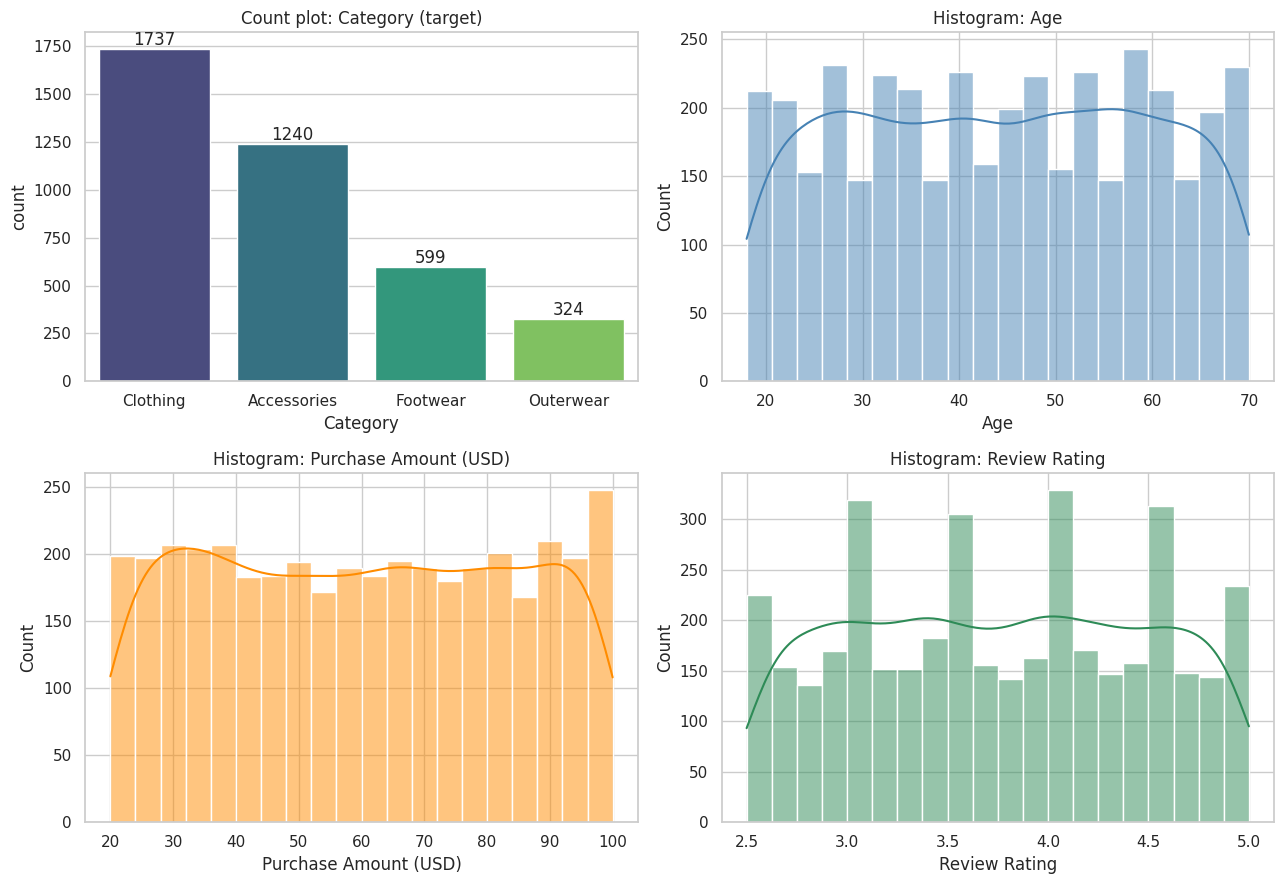

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# Count plot – target
order = df["Category"].value_counts().index
sns.countplot(data=df, x="Category", order=order, palette="viridis", ax=axes[0, 0])
axes[0, 0].set_title("Count plot: Category (target)")
for p in axes[0, 0].patches:
    axes[0, 0].annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")

# Histogram – age
sns.histplot(df["Age"], bins=20, kde=True, color="steelblue", ax=axes[0, 1])
axes[0, 1].set_title("Histogram: Age")

# Histogram – purchase amount
sns.histplot(df["Purchase Amount (USD)"], bins=20, kde=True, color="darkorange", ax=axes[1, 0])
axes[1, 0].set_title("Histogram: Purchase Amount (USD)")

# Histogram – review rating
sns.histplot(df["Review Rating"], bins=20, kde=True, color="seagreen", ax=axes[1, 1])
axes[1, 1].set_title("Histogram: Review Rating")
plt.tight_layout(); plt.show()

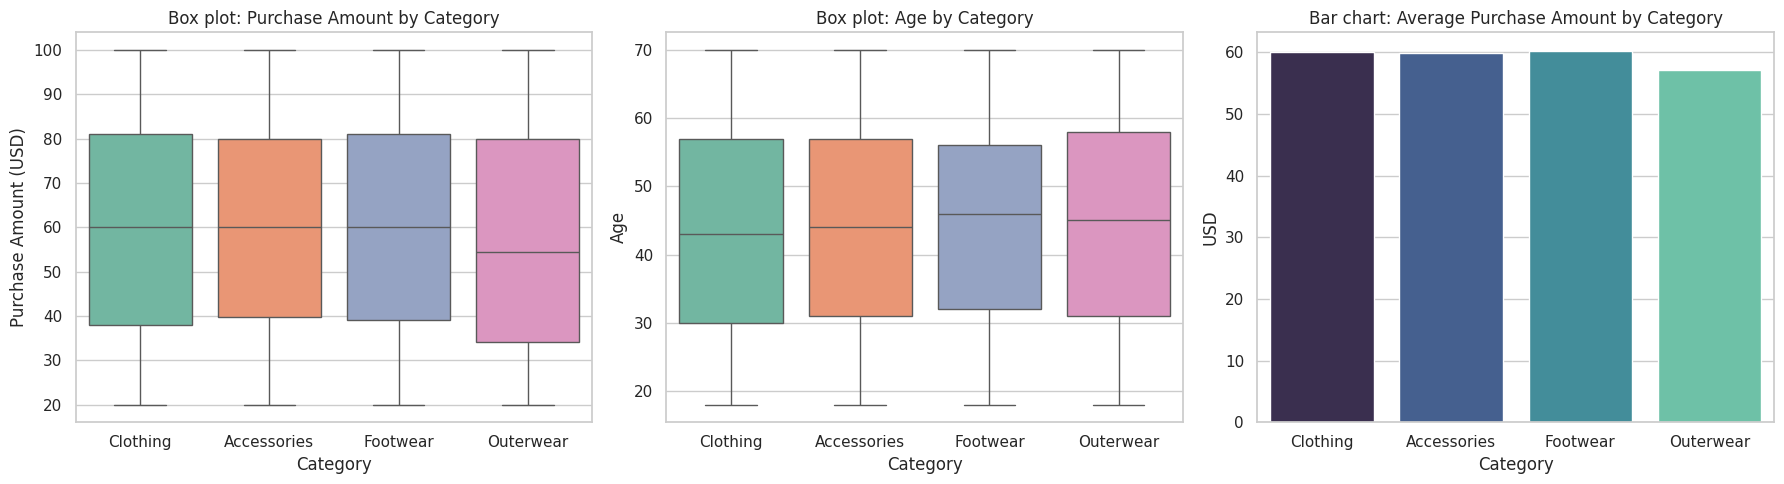

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Box plots
sns.boxplot(data=df, x="Category", y="Purchase Amount (USD)", order=order, palette="Set2", ax=axes[0])
axes[0].set_title("Box plot: Purchase Amount by Category")
sns.boxplot(data=df, x="Category", y="Age", order=order, palette="Set2", ax=axes[1])
axes[1].set_title("Box plot: Age by Category")

# Bar chart – average spend
avg = df.groupby("Category")["Purchase Amount (USD)"].mean().reindex(order)
sns.barplot(x=avg.index, y=avg.values, palette="mako", ax=axes[2])
axes[2].set_title("Bar chart: Average Purchase Amount by Category"); axes[2].set_ylabel("USD")
plt.tight_layout(); plt.show()

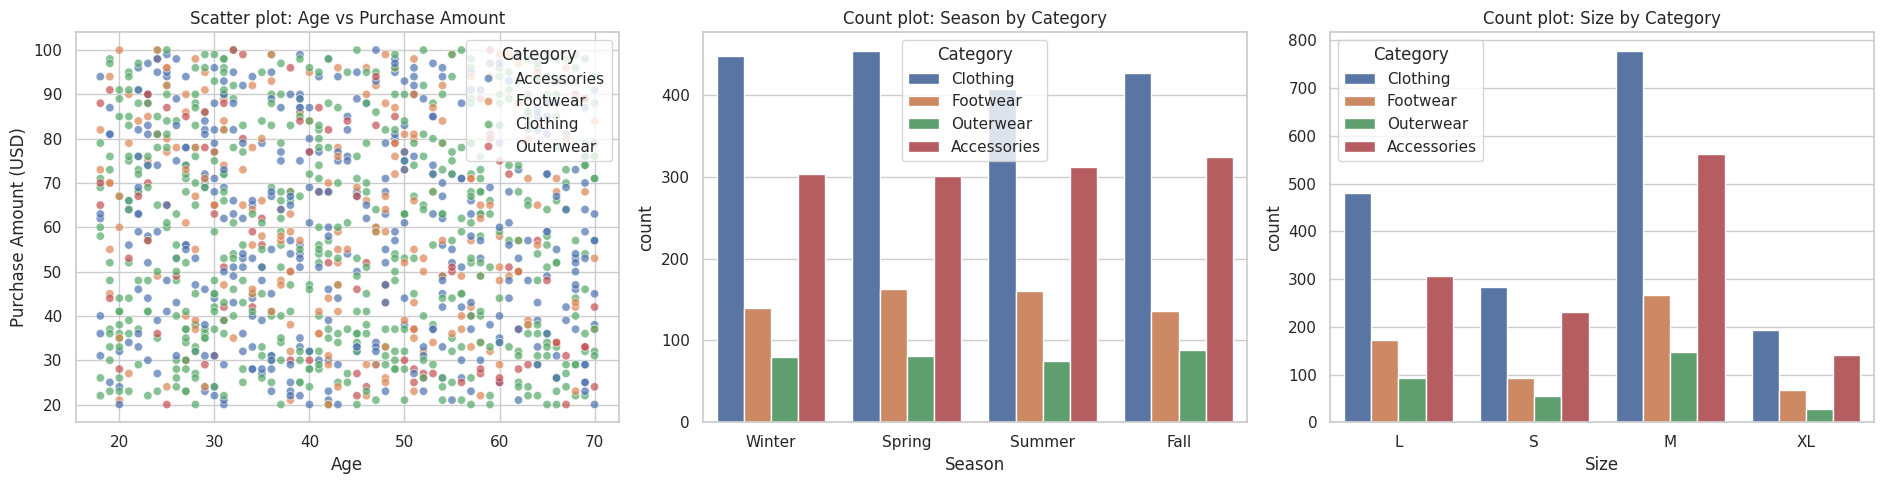

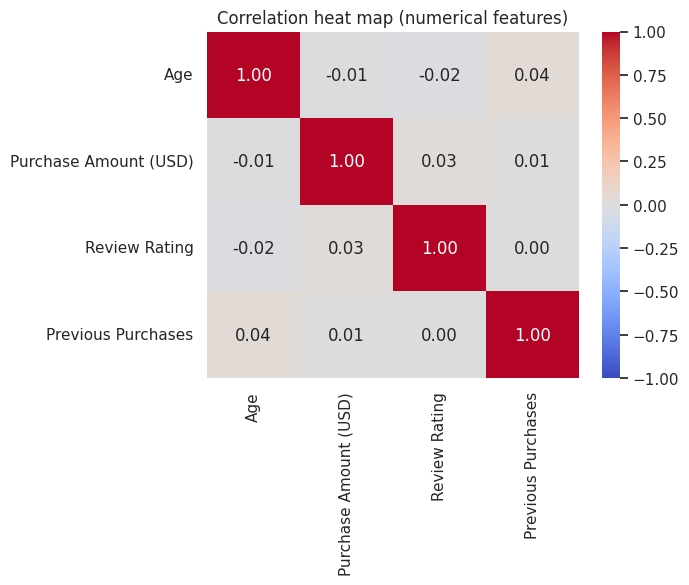

Category
Accessories    [Handbag, Sunglasses, Jewelry, Scarf, Hat, Bac...
Clothing       [Blouse, Sweater, Jeans, Shirt, Shorts, Dress,...
Footwear                       [Sandals, Sneakers, Shoes, Boots]
Outerwear                                         [Coat, Jacket]


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5))

# Scatter plot
sns.scatterplot(data=df.sample(1200, random_state=1), x="Age", y="Purchase Amount (USD)",
                hue="Category", alpha=.7, ax=axes[0])
axes[0].set_title("Scatter plot: Age vs Purchase Amount")

# Count plots with the target
sns.countplot(data=df, x="Season", hue="Category", ax=axes[1])
axes[1].set_title("Count plot: Season by Category")
sns.countplot(data=df, x="Size", hue="Category", ax=axes[2])
axes[2].set_title("Count plot: Size by Category")
plt.tight_layout(); plt.show()

# Correlation heat map
plt.figure(figsize=(6, 4.5))
sns.heatmap(df[num_cols].corr(), annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.title("Correlation heat map (numerical features)")
plt.show()

# Items inside each category
print(df.groupby("Category")["Item Purchased"].unique().to_string())

**EDA insights**
- The classes are imbalanced (Clothing is the largest, Outerwear the smallest).
- Age, price and rating are spread almost uniformly and **look very similar across all four categories**; correlations between numeric features are close to 0.
- Every `Item Purchased` belongs to exactly **one** category (e.g. Sneakers → Footwear, Jacket → Outerwear).

## 6. Feature Selection / Feature Engineering

Max #categories per item: 1 (1 = item fully determines category)


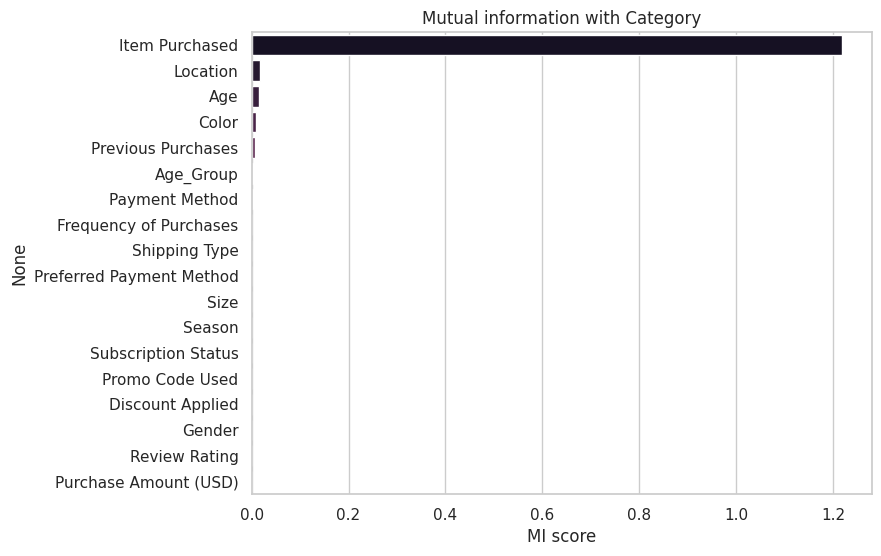

In [8]:
# Does the item name alone determine the category?
print("Max #categories per item:", df.groupby("Item Purchased")["Category"].nunique().max(), "(1 = item fully determines category)")

# New feature: age group
AGE_BINS   = [17, 25, 35, 45, 55, 70]
AGE_LABELS = ["18-25", "26-35", "36-45", "46-55", "56-70"]
df["Age_Group"] = pd.cut(df["Age"], bins=AGE_BINS, labels=AGE_LABELS).astype(str)

# How much information does each feature carry about the target? (mutual information)
tmp = df.drop(columns=["Customer ID", "Category"]).copy()
is_discrete = [c not in num_cols for c in tmp.columns]
for c in tmp.columns[is_discrete]:
    tmp[c] = tmp[c].astype("category").cat.codes
mi = pd.Series(mutual_info_classif(tmp, df["Category"], discrete_features=is_discrete, random_state=RANDOM_STATE),
               index=tmp.columns).sort_values(ascending=False)
plt.figure(figsize=(8, 6)); sns.barplot(x=mi.values, y=mi.index, palette="rocket")
plt.title("Mutual information with Category"); plt.xlabel("MI score"); plt.show()

**Which features are used / removed, and why?**

| Decision | Features | Reason |
|---|---|---|
| ❌ Removed | `Customer ID` | Just an identifier, no predictive meaning |
| ❌ Removed | `Promo Code Used` | Exact duplicate of `Discount Applied` |
| ✅ New feature | `Age_Group` | Bins `Age` into 5 groups (18-25 … 56-70) |
| ✅ Used | Age, Purchase Amount, Review Rating, Previous Purchases | Numerical (scaled) |
| ✅ Used | Gender, Location, Size, Color, Season, Subscription, Payment, Shipping, Discount, Preferred Payment, Frequency, Age_Group | Categorical (one-hot) |
| ⚠️ **Experiment** | `Item Purchased` | It **fully determines** the category (each item belongs to exactly one category). Using it is legitimate for *catalogue auto-categorisation* (the item name is known) but would be **data leakage** for a model that tries to guess from customer behaviour alone. |

The mutual-information chart shows that **every feature except `Item Purchased` carries almost no information** about the category, so we run **two experiments** and compare them honestly:
- **Experiment A – behaviour only** (without `Item Purchased`)
- **Experiment B – catalogue auto-categorisation** (with `Item Purchased`)

## 7. Train–Test Split (80 % / 20 %)

In [9]:
y = df["Category"]
X = df.drop(columns=["Category", "Customer ID", "Promo Code Used"])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)   # stratify keeps class ratios equal

print("Training set:", X_train.shape, "| Test set:", X_test.shape)
print("\nClass share (%)")
display(pd.DataFrame({"train": y_train.value_counts(normalize=True) * 100,
                      "test":  y_test.value_counts(normalize=True) * 100}).round(1))

Training set: (3120, 17) | Test set: (780, 17)

Class share (%)


,train,test
Category,,
Clothing,44.6,44.5
Accessories,31.8,31.8
Footwear,15.4,15.4
Outerwear,8.3,8.3


## 8. Model Building
We compare 6 algorithms (with a majority-class **baseline** to see whether the models learn anything real) using **5-fold stratified cross-validation** on the training data, scored by **macro-F1**.

In [10]:
NUM_FEATURES = ["Age", "Purchase Amount (USD)", "Review Rating", "Previous Purchases"]
CAT_BASE = ["Gender", "Location", "Size", "Color", "Season", "Subscription Status", "Payment Method",
            "Shipping Type", "Discount Applied", "Preferred Payment Method",
            "Frequency of Purchases", "Age_Group"]

MODELS = {
    "Baseline (most frequent)": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression":      LogisticRegression(max_iter=2000, class_weight="balanced"),
    "KNN":                      KNeighborsClassifier(n_neighbors=15),
    "Decision Tree":            DecisionTreeClassifier(max_depth=8, class_weight="balanced", random_state=RANDOM_STATE),
    "Random Forest":            RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                                       n_jobs=-1, random_state=RANDOM_STATE),
    "Hist Gradient Boosting":   HistGradientBoostingClassifier(random_state=RANDOM_STATE),
}

def make_preprocessor(cat_features):
    return ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_features),
        ("num", StandardScaler(), NUM_FEATURES),
    ], sparse_threshold=0)

def run_experiment(include_item):
    cat_features = CAT_BASE + (["Item Purchased"] if include_item else [])
    features = NUM_FEATURES + cat_features
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    rows, fitted = [], {}
    for name, model in MODELS.items():
        pipe = Pipeline([("prep", make_preprocessor(cat_features)), ("model", clone(model))])
        cv_f1 = cross_val_score(pipe, X_train[features], y_train, cv=cv, scoring="f1_macro").mean()
        pipe.fit(X_train[features], y_train)
        pred = pipe.predict(X_test[features])
        rows.append({"Model": name,
                     "CV macro-F1": round(cv_f1, 4),
                     "Test accuracy": round(accuracy_score(y_test, pred), 4),
                     "Test macro-F1": round(f1_score(y_test, pred, average="macro"), 4)})
        fitted[name] = pipe
    res = pd.DataFrame(rows).sort_values("CV macro-F1", ascending=False, kind="stable").reset_index(drop=True)
    return res, fitted, features, cat_features

print("Experiment A – customer behaviour only (NO 'Item Purchased')")
res_A, models_A, feats_A, cats_A = run_experiment(include_item=False)
display(res_A)

print("Experiment B – catalogue auto-categorisation (WITH 'Item Purchased')")
res_B, models_B, feats_B, cats_B = run_experiment(include_item=True)
display(res_B)

Experiment A – customer behaviour only (NO 'Item Purchased')


,Model,CV macro-F1,Test accuracy,Test macro-F1
0,Hist Gradient Boosting,0.2298,0.3974,0.2331
1,Logistic Regression,0.2211,0.2410,0.2179
2,KNN,0.2167,0.4000,0.2156
3,Decision Tree,0.2058,0.2654,0.2006
4,Random Forest,0.1776,0.4295,0.1704
5,Baseline (most frequent),0.1541,0.4449,0.1539


Experiment B – catalogue auto-categorisation (WITH 'Item Purchased')


,Model,CV macro-F1,Test accuracy,Test macro-F1
0,Logistic Regression,1.0000,1.0000,1.0000
1,Random Forest,1.0000,1.0000,1.0000
2,Hist Gradient Boosting,1.0000,1.0000,1.0000
3,Decision Tree,0.8035,0.7538,0.7879
4,KNN,0.3525,0.5436,0.3607
5,Baseline (most frequent),0.1541,0.4449,0.1539


**Reading the two tables**
- **Experiment A:** no model gets above ~43 % test accuracy, i.e. none beats the 44 % you get by always guessing "Clothing", and macro-F1 stays low (~0.2). Age, price, season, payment method etc. simply do not reveal the product category in this dataset (matches the mutual-information chart). This is an important, honest finding.
- **Experiment B:** once the item name is available, models reach ~100 % — but that is because item → category is a fixed lookup. This is exactly what a catalogue auto-tagging tool needs, so **Experiment B is the model we deploy**.

In [11]:
# ---- Choose the final model (Experiment B, best CV score; ties → first in the sorted table) ----
final_name  = res_B.iloc[0]["Model"]
final_model = models_B[final_name]
FEATURES, CAT_FEATURES = feats_B, cats_B
print("Final model:", final_name)

Final model: Logistic Regression


## 9. Model Evaluation

In [12]:
pred  = final_model.predict(X_test[FEATURES])
proba = final_model.predict_proba(X_test[FEATURES])
classes = final_model.classes_

print(f"Accuracy          : {accuracy_score(y_test, pred):.4f}")
print(f"Precision (macro) : {precision_score(y_test, pred, average='macro'):.4f}")
print(f"Recall (macro)    : {recall_score(y_test, pred, average='macro'):.4f}")
print(f"F1-score (macro)  : {f1_score(y_test, pred, average='macro'):.4f}")
print(f"F1-score (weighted): {f1_score(y_test, pred, average='weighted'):.4f}")

y_bin = label_binarize(y_test, classes=classes)
print(f"ROC-AUC (one-vs-rest, macro): {roc_auc_score(y_bin, proba, average='macro'):.4f}")

print("\n--- Classification report ---")
print(classification_report(y_test, pred, digits=3))

Accuracy          : 1.0000
Precision (macro) : 1.0000
Recall (macro)    : 1.0000
F1-score (macro)  : 1.0000
F1-score (weighted): 1.0000
ROC-AUC (one-vs-rest, macro): 1.0000

--- Classification report ---
              precision    recall  f1-score   support

 Accessories      1.000     1.000     1.000       248
    Clothing      1.000     1.000     1.000       347
    Footwear      1.000     1.000     1.000       120
   Outerwear      1.000     1.000     1.000        65

    accuracy                          1.000       780
   macro avg      1.000     1.000     1.000       780
weighted avg      1.000     1.000     1.000       780



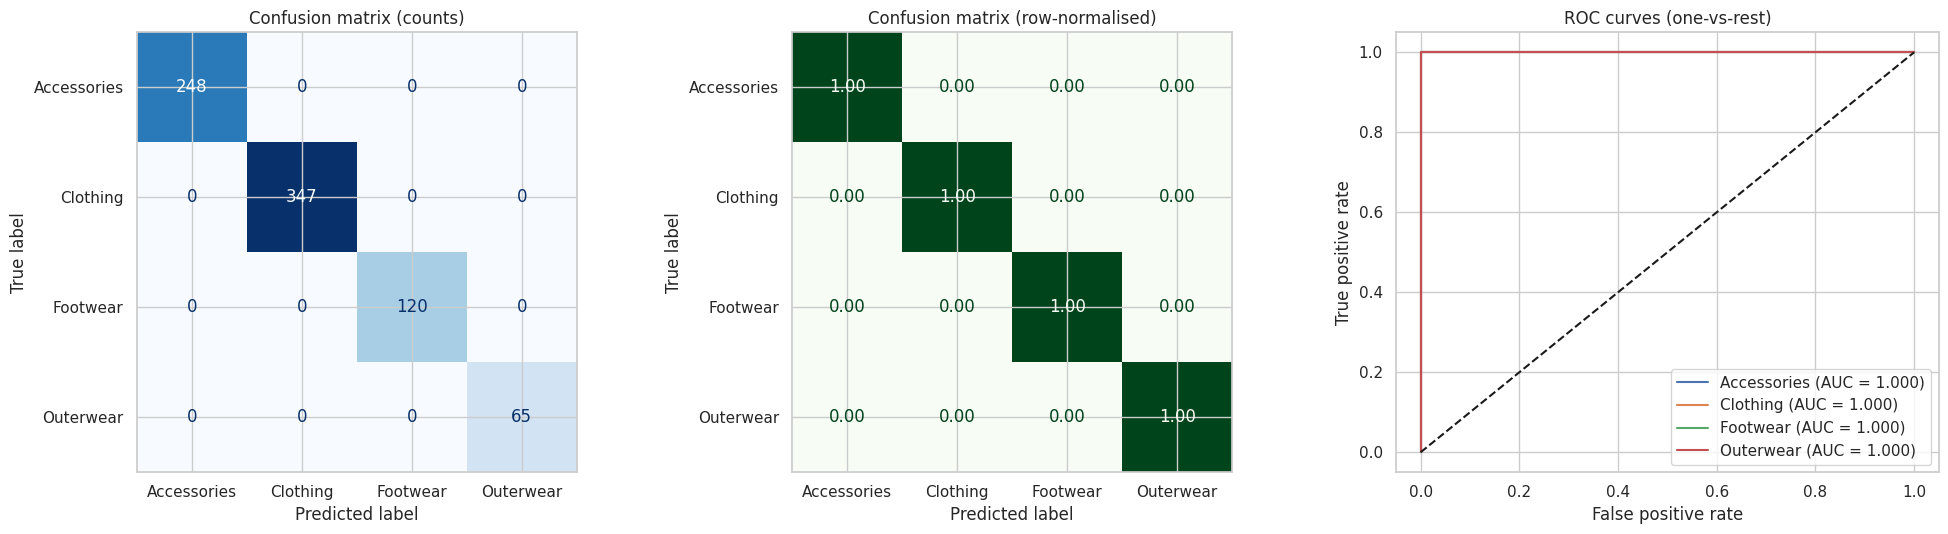

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))

# Confusion matrix (counts)
ConfusionMatrixDisplay.from_predictions(y_test, pred, labels=classes, cmap="Blues", ax=axes[0], colorbar=False)
axes[0].set_title("Confusion matrix (counts)")

# Confusion matrix (normalised)
ConfusionMatrixDisplay.from_predictions(y_test, pred, labels=classes, normalize="true",
                                        cmap="Greens", ax=axes[1], colorbar=False, values_format=".2f")
axes[1].set_title("Confusion matrix (row-normalised)")

# ROC curves (one-vs-rest)
for i, c in enumerate(classes):
    fpr, tpr, _ = roc_curve(y_bin[:, i], proba[:, i])
    axes[2].plot(fpr, tpr, label=f"{c} (AUC = {auc(fpr, tpr):.3f})")
axes[2].plot([0, 1], [0, 1], "k--"); axes[2].set_title("ROC curves (one-vs-rest)")
axes[2].set_xlabel("False positive rate"); axes[2].set_ylabel("True positive rate"); axes[2].legend()
plt.tight_layout(); plt.show()

In [14]:
# Side-by-side summary of both experiments (best model of each)
summary = pd.DataFrame({
    "Experiment": ["A: behaviour only", "B: with Item Purchased (deployed)"],
    "Best model": [res_A.iloc[0]["Model"], res_B.iloc[0]["Model"]],
    "Test accuracy": [res_A.iloc[0]["Test accuracy"], res_B.iloc[0]["Test accuracy"]],
    "Test macro-F1": [res_A.iloc[0]["Test macro-F1"], res_B.iloc[0]["Test macro-F1"]],
})
summary["Majority-class baseline accuracy"] = round(y_test.value_counts(normalize=True).max(), 4)
display(summary)

,Experiment,Best model,Test accuracy,Test macro-F1,Majority-class baseline accuracy
0,A: behaviour only,Hist Gradient Boosting,0.3974,0.2331,0.4449
1,B: with Item Purchased (deployed),Logistic Regression,1.0000,1.0000,0.4449


**Interpretation**
- Accuracy, precision, recall, F1, the confusion matrix and ROC-AUC are all reported; for imbalanced data macro-F1 is the fairest single number.
- The deployed model separates all 4 classes essentially perfectly **because the item name decides the category**. It should be understood as an automatic catalogue-tagging tool, not as a way to read customers' minds.
- With behaviour-only features (Experiment A) the dataset gives accuracy near the majority-class baseline — so category cannot be reliably predicted from customer behaviour here. (This dataset appears to be synthetic.)

## 10. Save the Final Model

In [15]:
# Save the full pipeline (preprocessing + model)
joblib.dump(final_model, "category_model.joblib")

# Save metadata used by the website (feature names, dropdown options, slider ranges)
input_order = NUM_FEATURES + [c for c in CAT_FEATURES if c != "Age_Group"]
meta = {
    "model_name": final_name,
    "classes": list(classes),
    "features": FEATURES,
    "input_order": input_order,
    "age_bins": AGE_BINS, "age_labels": AGE_LABELS,
    "num": {
        "Age":                   {"min": 18, "max": 70,  "step": 1,   "default": 40},
        "Purchase Amount (USD)": {"min": 20, "max": 100, "step": 1,   "default": 60},
        "Review Rating":         {"min": 2.5, "max": 5.0, "step": 0.1, "default": 3.8},
        "Previous Purchases":    {"min": 1,  "max": 50,  "step": 1,   "default": 25},
    },
    "cat": {c: {"options": sorted(df[c].unique().tolist()), "default": df[c].mode()[0]}
            for c in input_order if c in CAT_FEATURES},
    "test_accuracy": float(accuracy_score(y_test, pred)),
    "test_macro_f1": float(f1_score(y_test, pred, average="macro")),
}
with open("model_meta.json", "w") as f:
    json.dump(meta, f, indent=2)

# Save extra files used by the dashboard
roc = {}
for i, c in enumerate(classes):
    fpr, tpr, _ = roc_curve(y_bin[:, i], proba[:, i])
    roc[c] = {"fpr": np.round(fpr, 4).tolist(), "tpr": np.round(tpr, 4).tolist(), "auc": float(auc(fpr, tpr))}
metrics = {
    "classes": list(classes),
    "accuracy":  float(accuracy_score(y_test, pred)),
    "precision": float(precision_score(y_test, pred, average="macro")),
    "recall":    float(recall_score(y_test, pred, average="macro")),
    "f1":        float(f1_score(y_test, pred, average="macro")),
    "roc_auc":   float(roc_auc_score(y_bin, proba, average="macro")),
    "confusion_matrix": confusion_matrix(y_test, pred, labels=classes).tolist(),
    "roc": roc,
    "res_A": res_A.to_dict("records"),
    "res_B": res_B.to_dict("records"),
}
with open("metrics.json", "w") as f:
    json.dump(metrics, f)
df.drop(columns=["Promo Code Used"]).to_csv("dashboard_data.csv", index=False)

# Sanity check: reload and compare predictions
loaded = joblib.load("category_model.joblib")
assert (loaded.predict(X_test[FEATURES]) == pred).all()
print("✅ Saved: category_model.joblib, model_meta.json, metrics.json, dashboard_data.csv")

try:
    from google.colab import files
    files.download("category_model.joblib"); files.download("model_meta.json"); files.download("metrics.json"); files.download("dashboard_data.csv")
except Exception:
    pass

✅ Saved: category_model.joblib, model_meta.json, metrics.json, dashboard_data.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 11. Deployment (Mandatory) — Interactive Dashboard Website
The next cell writes `app.py` (a multi-page dashboard website that loads the saved model) and launches it.

**Pages:** 📊 Dashboard (filters + KPI cards + 6 interactive charts) · 🔮 Predict · 🏆 Model Performance · ℹ️ About

Click the **public `https://xxxx.gradio.live` link** printed in the output to open it in a new browser tab (works on phones too, valid ~72 hours while Colab is running).

*Permanent hosting (optional):* create a free **Hugging Face Space** (SDK = Gradio) and upload `app.py`, `category_model.joblib`, `model_meta.json`, `metrics.json`, `dashboard_data.csv` and a `requirements.txt` containing `gradio`, `plotly`, `scikit-learn`, `pandas`, `joblib`.

In [16]:
APP_CODE = r'''
import json, inspect
import joblib
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import gradio as gr

# ------------------------------------------------------------------ load artefacts
model = joblib.load("category_model.joblib")
meta  = json.load(open("model_meta.json"))
M     = json.load(open("metrics.json"))
data  = pd.read_csv("dashboard_data.csv")

PALETTE = {"Clothing": "#6366f1", "Accessories": "#ec4899", "Footwear": "#14b8a6", "Outerwear": "#f59e0b"}
EMOJI   = {"Clothing": "👕", "Accessories": "💍", "Footwear": "👟", "Outerwear": "🧥"}

def style(fig, h=350, title=None):
    fig.update_layout(template="plotly_white", height=h, margin=dict(l=10, r=10, t=55, b=10),
                      title=dict(text=title, font=dict(size=16)) if title else None,
                      legend_title_text="", paper_bgcolor="white", plot_bgcolor="white",
                      font=dict(family="Inter, Segoe UI, sans-serif", color="#1e293b"))
    return fig

def kpi(label, value, icon, color):
    return (f'<div class="kpi" style="border-top:4px solid {color}">'
            f'<div class="kpi-icon">{icon}</div><div class="kpi-val">{value}</div>'
            f'<div class="kpi-label">{label}</div></div>')

# ------------------------------------------------------------------ dashboard tab
def dashboard(season, gender, subscribed):
    d = data
    if season != "All":     d = d[d["Season"] == season]
    if gender != "All":     d = d[d["Gender"] == gender]
    if subscribed != "All": d = d[d["Subscription Status"] == subscribed]

    if len(d) == 0:
        blank = style(go.Figure(), title="No data for this filter")
        return ('<div class="kpi-row">' + kpi("Records", 0, "🧾", "#6366f1") + "</div>",
                blank, blank, blank, blank, blank, blank)

    top_cat = d["Category"].value_counts().idxmax()
    kpis = ('<div class="kpi-row">'
            + kpi("Total purchases", f"{len(d):,}", "🧾", "#6366f1")
            + kpi("Avg purchase (USD)", f"${d['Purchase Amount (USD)'].mean():.2f}", "💵", "#10b981")
            + kpi("Avg review rating", f"{d['Review Rating'].mean():.2f} ⭐", "⭐", "#f59e0b")
            + kpi("Avg customer age", f"{d['Age'].mean():.1f}", "🎂", "#ec4899")
            + kpi("Top category", f"{EMOJI[top_cat]} {top_cat}", "🏆", "#14b8a6")
            + "</div>")

    counts = d["Category"].value_counts()
    f1 = px.pie(names=counts.index, values=counts.values, hole=0.55,
                color=counts.index, color_discrete_map=PALETTE)
    f1.update_traces(textinfo="percent+label")
    style(f1, title="Category share")

    g = d.groupby("Category")["Purchase Amount (USD)"].mean().round(2).reset_index()
    f2 = px.bar(g, x="Category", y="Purchase Amount (USD)", color="Category",
                color_discrete_map=PALETTE, text_auto=".1f")
    f2.update_layout(showlegend=False); style(f2, title="Average purchase amount (USD)")

    g = d.groupby(["Season", "Category"]).size().reset_index(name="Purchases")
    f3 = px.bar(g, x="Season", y="Purchases", color="Category", barmode="group", color_discrete_map=PALETTE,
                category_orders={"Season": ["Spring", "Summer", "Fall", "Winter"]})
    style(f3, title="Purchases by season")

    f4 = px.histogram(d, x="Age", color="Category", nbins=20, barmode="overlay", opacity=0.65,
                      color_discrete_map=PALETTE)
    style(f4, title="Age distribution by category")

    items = d["Item Purchased"].value_counts().head(10).sort_values()
    f5 = px.bar(x=items.values, y=items.index, orientation="h", color_discrete_sequence=["#6366f1"])
    f5.update_layout(xaxis_title="Purchases", yaxis_title=""); style(f5, title="Top 10 items")

    f6 = px.box(d, x="Category", y="Review Rating", color="Category", color_discrete_map=PALETTE)
    f6.update_layout(showlegend=False); style(f6, title="Review rating by category")

    return kpis, f1, f2, f3, f4, f5, f6

# ------------------------------------------------------------------ predict tab
def predict(*values):
    row = dict(zip(meta["input_order"], values))
    row["Age_Group"] = str(pd.cut([row["Age"]], bins=meta["age_bins"], labels=meta["age_labels"])[0])
    X = pd.DataFrame([row])[meta["features"]]
    proba = model.predict_proba(X)[0]
    probs = dict(zip(model.classes_, [float(p) for p in proba]))
    top = max(probs, key=probs.get)

    card = (f'<div class="result" style="border-left:8px solid {PALETTE.get(top, "#6366f1")}">'
            f'<div class="result-emoji">{EMOJI.get(top, "🛍️")}</div>'
            f'<div><div class="result-small">Predicted category</div>'
            f'<div class="result-label">{top}</div>'
            f'<div class="result-conf">Confidence: {probs[top] * 100:.1f}%</div></div></div>')

    order = sorted(probs, key=probs.get)
    fig = go.Figure(go.Bar(x=[probs[c] * 100 for c in order], y=order, orientation="h",
                           marker_color=[PALETTE.get(c, "#6366f1") for c in order],
                           text=[f"{probs[c] * 100:.1f}%" for c in order], textposition="auto"))
    fig.update_xaxes(range=[0, 100], title="Probability (%)")
    style(fig, h=300, title="Class probabilities")
    return card, fig

# ------------------------------------------------------------------ performance tab (static)
def perf_cards():
    items = [("Accuracy", M["accuracy"], "#6366f1"), ("Precision (macro)", M["precision"], "#10b981"),
             ("Recall (macro)", M["recall"], "#f59e0b"), ("F1-score (macro)", M["f1"], "#ec4899"),
             ("ROC-AUC (OvR)", M["roc_auc"], "#14b8a6")]
    return '<div class="kpi-row">' + "".join(kpi(n, f"{v:.3f}", "📈", c) for n, v, c in items) + "</div>"

def cm_figure():
    fig = px.imshow(M["confusion_matrix"], x=M["classes"], y=M["classes"], text_auto=True,
                    color_continuous_scale="Blues", labels=dict(x="Predicted", y="Actual", color="Count"))
    return style(fig, h=400, title="Confusion matrix (test set)")

def roc_figure():
    fig = go.Figure()
    for c, r in M["roc"].items():
        fig.add_trace(go.Scatter(x=r["fpr"], y=r["tpr"], mode="lines", name=f"{c} (AUC {r['auc']:.3f})",
                                 line=dict(color=PALETTE.get(c), width=3)))
    fig.add_trace(go.Scatter(x=[0, 1], y=[0, 1], mode="lines", line=dict(dash="dash", color="grey"),
                             showlegend=False))
    fig.update_xaxes(title="False positive rate"); fig.update_yaxes(title="True positive rate")
    return style(fig, h=400, title="ROC curves (one-vs-rest)")

NOTE = (
    '<div class="note"><b>How to read these results.</b> In this dataset every <i>Item Purchased</i> belongs to '
    'exactly one category, so the deployed model (which receives the item name) is effectively a catalogue '
    'auto-tagger and scores ~100%. When the item name is hidden (Experiment A, table below) no model beats the '
    '"always guess Clothing" baseline, which means category cannot be predicted from customer behaviour alone here.</div>')

# ------------------------------------------------------------------ styling
CSS = (
    ".gradio-container{max-width:1250px !important;margin:auto;background:#f1f5f9 !important}"
    ".hero{background:linear-gradient(120deg,#4f46e5,#7c3aed 55%,#ec4899);color:#fff;padding:34px 38px;"
    "border-radius:18px;margin-bottom:6px;box-shadow:0 10px 30px rgba(79,70,229,.30)}"
    ".hero h1{margin:0;font-size:2.2rem;font-weight:800;color:#fff}"
    ".hero p{margin:8px 0 0;font-size:1.05rem;opacity:.92;color:#fff}"
    ".pill{display:inline-block;background:rgba(255,255,255,.20);padding:4px 14px;border-radius:999px;"
    "font-size:.85rem;margin:14px 8px 0 0;color:#fff}"
    ".kpi-row{display:grid;grid-template-columns:repeat(auto-fit,minmax(170px,1fr));gap:14px;margin:6px 0}"
    ".kpi{background:#fff;border-radius:14px;padding:16px 18px;box-shadow:0 2px 10px rgba(15,23,42,.07)}"
    ".kpi-icon{font-size:1.4rem}"
    ".kpi-val{font-size:1.6rem;font-weight:800;color:#0f172a;margin-top:2px}"
    ".kpi-label{font-size:.85rem;color:#64748b;margin-top:2px}"
    ".result{display:flex;align-items:center;gap:22px;background:#fff;border-radius:16px;padding:24px 28px;"
    "box-shadow:0 2px 12px rgba(15,23,42,.08)}"
    ".result-emoji{font-size:3.6rem}"
    ".result-small{color:#64748b;font-size:.9rem}"
    ".result-label{font-size:2.2rem;font-weight:800;color:#0f172a}"
    ".result-conf{color:#475569;font-size:1.05rem}"
    ".note{background:#eef2ff;border-left:5px solid #6366f1;padding:14px 18px;border-radius:10px;"
    "color:#1e293b;margin:8px 0}"
    ".footer{text-align:center;color:#64748b;font-size:.85rem;padding:18px 0 6px}"
    "button.primary,.primary{background:linear-gradient(90deg,#6366f1,#8b5cf6) !important;border:none !important;"
    "color:#fff !important;font-weight:700 !important}"
    "button[role=tab]{font-weight:700 !important;font-size:1rem !important}"
)

HEADER = (
    '<div class="hero"><h1>🛍️ ShopSense — Category Prediction Dashboard</h1>'
    '<p>Explore shopping trends and predict the product category of a purchase with machine learning.</p>'
    f'<span class="pill">🤖 {meta["model_name"]}</span>'
    f'<span class="pill">🎯 Accuracy {M["accuracy"] * 100:.1f}%</span>'
    f'<span class="pill">🧾 {len(data):,} purchases</span>'
    '<span class="pill">🗂️ 4 classes</span></div>')

ABOUT = """
### About this project
**Problem:** multiclass classification — predict a purchase's product **category**
(Clothing, Accessories, Footwear, Outerwear).

**Users:** e-commerce catalogue teams, merchandisers and analysts who want automatic product tagging.

**Dataset:** Customer Shopping Trends Dataset (Kaggle) — 3,900 purchases, 18 columns.

**Pipeline:** cleaning → EDA → feature engineering (`Age_Group`) → 80/20 stratified split →
one-hot encoding + scaling → 6 algorithms compared with 5-fold CV → best model saved with `joblib` → this app.

**Important:** `Item Purchased` determines `Category` in this dataset, so the model is a catalogue
auto-categoriser. Without the item name, customer-behaviour features alone cannot predict the category.
"""

# ------------------------------------------------------------------ build the website
CSS_IN_BLOCKS = "css" in inspect.signature(gr.Blocks.__init__).parameters
blocks_kwargs = {"title": "ShopSense Dashboard"}
if CSS_IN_BLOCKS:
    blocks_kwargs["css"] = CSS

with gr.Blocks(**blocks_kwargs) as demo:
    gr.HTML(HEADER)
    with gr.Tabs():

        with gr.Tab("📊 Dashboard"):
            with gr.Row():
                f_season = gr.Dropdown(["All"] + ["Spring", "Summer", "Fall", "Winter"], value="All", label="Season")
                f_gender = gr.Dropdown(["All", "Female", "Male"], value="All", label="Gender")
                f_sub    = gr.Dropdown(["All", "Yes", "No"], value="All", label="Subscribed")
            kpi_out = gr.HTML()
            with gr.Row():
                p1 = gr.Plot(show_label=False); p2 = gr.Plot(show_label=False)
            with gr.Row():
                p3 = gr.Plot(show_label=False); p4 = gr.Plot(show_label=False)
            with gr.Row():
                p5 = gr.Plot(show_label=False); p6 = gr.Plot(show_label=False)
            filters = [f_season, f_gender, f_sub]
            outs = [kpi_out, p1, p2, p3, p4, p5, p6]
            for f in filters:
                f.change(dashboard, filters, outs)
            demo.load(dashboard, filters, outs)

        with gr.Tab("🔮 Predict"):
            with gr.Row():
                with gr.Column(scale=1):
                    gr.Markdown("### Enter purchase details")
                    inputs = []
                    for name in meta["input_order"]:
                        if name in meta["num"]:
                            s = meta["num"][name]
                            inputs.append(gr.Slider(s["min"], s["max"], value=s["default"], step=s["step"], label=name))
                        else:
                            c = meta["cat"][name]
                            inputs.append(gr.Dropdown(c["options"], value=c["default"], label=name))
                    btn = gr.Button("🔮 Predict category", variant="primary", size="lg")
                with gr.Column(scale=1):
                    gr.Markdown("### Prediction")
                    out_card = gr.HTML()
                    out_plot = gr.Plot(show_label=False)
            btn.click(predict, inputs, [out_card, out_plot])

        with gr.Tab("🏆 Model Performance"):
            gr.HTML(perf_cards())
            gr.HTML(NOTE)
            with gr.Row():
                gr.Plot(value=cm_figure(), show_label=False)
                gr.Plot(value=roc_figure(), show_label=False)
            gr.Markdown("### Experiment B — with `Item Purchased` (deployed)")
            gr.Dataframe(value=pd.DataFrame(M["res_B"]), interactive=False)
            gr.Markdown("### Experiment A — customer behaviour only (no item name)")
            gr.Dataframe(value=pd.DataFrame(M["res_A"]), interactive=False)

        with gr.Tab("ℹ️ About"):
            gr.Markdown(ABOUT)

    gr.HTML('<div class="footer">Built with scikit-learn · Plotly · Gradio</div>')

if __name__ == "__main__":
    launch_kwargs = {"share": True}
    if not CSS_IN_BLOCKS:
        launch_kwargs["css"] = CSS
    demo.launch(**launch_kwargs)

'''

with open("app.py", "w") as f:
    f.write(APP_CODE)
with open("requirements.txt", "w") as f:
    f.write("gradio\nplotly\nscikit-learn\npandas\nnumpy\njoblib\n")

exec(APP_CODE)      # launches the website – click the public gradio.live link

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://5106fb1d6d2dc77ac3.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


---
### ✅ Project summary
| Step | Done |
|---|---|
| Problem definition, dataset, understanding | ✔ |
| Preprocessing, EDA, feature engineering | ✔ |
| 80/20 stratified split | ✔ |
| 6 algorithms + baseline, cross-validation | ✔ |
| Accuracy / Precision / Recall / F1 / Confusion matrix / ROC-AUC | ✔ |
| Model saved (`.joblib`) | ✔ |
| Website deployed (Gradio) | ✔ |